<a href="https://colab.research.google.com/github/MaanyaGupta/CSET343/blob/main/Lab5_E23CSEU0728_CSET343.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Assignment 5: Multiclass Classification
**Course:** CSET343 – AI in Healthcare | B.Tech, 4th Year, Semester VII
**Dataset chosen:** Dermatology (UCI) – 6 erythemato-squamous skin diseases

**Objective:** Explore, preprocess and model a multiclass medical dataset, train five different classifiers (Logistic Regression, KNN, SVM, Random Forest, Gradient Boosting), and compare them with accuracy, per-class precision/recall/F1, confusion matrices and one-vs-rest ROC/AUC.

**Target classes:** 1 = psoriasis, 2 = seborrheic dermatitis, 3 = lichen planus, 4 = pityriasis rosea, 5 = chronic dermatitis, 6 = pityriasis rubra pilaris.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score)

%matplotlib inline
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
sns.set_style("whitegrid")
RANDOM_STATE = 42

# Task 1: Data Acquisition and Exploration
## 1. Download and load the dataset

The UCI Dermatology data (366 patients, 34 features) is loaded from the PMLB repository copy on GitHub. If you have no internet access, place `dermatology.tsv.gz` (provided alongside this notebook) in the same folder and it is loaded from there instead.

In [ ]:
URL = "https://media.githubusercontent.com/media/EpistasisLab/pmlb/master/datasets/dermatology/dermatology.tsv.gz"
try:
    df = pd.read_csv(URL, sep="\t")
    print("Loaded from URL")
except Exception:
    df = pd.read_csv("dermatology.tsv.gz", sep="\t")
    print("Loaded from local file")

df = df.rename(columns={"target": "Class"})
class_names = {1: "Psoriasis", 2: "Seborrheic dermatitis", 3: "Lichen planus",
               4: "Pityriasis rosea", 5: "Chronic dermatitis", 6: "Pityriasis rubra pilaris"}
features = [c for c in df.columns if c != "Class"]

print("Shape:", df.shape, f"-> {len(df)} samples, {len(features)} features + target 'Class'")
df.head()

Loaded from URL
Shape: (366, 35) -> 366 samples, 34 features + target 'Class'


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,Class
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,43,2
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,58,1
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,15,3
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,29,1
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,34,3


**Feature meaning:** 12 clinical features (erythema, scaling, itching, ..., family history, age) and 22 histopathological features measured on the skin biopsy. All are graded 0–3 (0 = absent, 3 = most severe) except *family_history* (0/1) and *Age* (years).

## 2. Summary statistics

In [ ]:
summary = df[features].describe().T
summary["median"] = df[features].median()
summary = summary[["count", "mean", "median", "std", "min", "25%", "75%", "max"]]
summary.round(3)

,count,mean,median,std,min,25%,75%,max
erythema,366.0,2.068,2.0,0.665,0.0,2.0,2.0,3.0
scaling,366.0,1.795,2.0,0.702,0.0,1.0,2.0,3.0
definite_borders,366.0,1.549,2.0,0.908,0.0,1.0,2.0,3.0
itching,366.0,1.366,1.0,1.138,0.0,0.0,2.0,3.0
koebner_phenomenon,366.0,0.634,0.0,0.908,0.0,0.0,1.0,3.0
polygonal_papules,366.0,0.448,0.0,0.957,0.0,0.0,0.0,3.0
follicular_papules,366.0,0.167,0.0,0.571,0.0,0.0,0.0,3.0
oral_mucosal_involvement,366.0,0.377,0.0,0.834,0.0,0.0,0.0,3.0
knee_and_elbow_involvement,366.0,0.615,0.0,0.983,0.0,0.0,1.0,3.0
scalp_involvement,366.0,0.519,0.0,0.906,0.0,0.0,1.0,3.0


## 3. Missing values, duplicates and outliers

In [ ]:
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Age summary:", df["Age"].describe().round(2).to_dict())

# IQR rule applied per feature
Q1, Q3 = df[features].quantile(0.25), df[features].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df[features] < (Q1 - 1.5 * IQR)) | (df[features] > (Q3 + 1.5 * IQR))
oc = outlier_mask.sum()
print("\nFeatures with IQR-rule outliers:")
print(oc[oc > 0].sort_values(ascending=False))

Missing values: 0
Duplicate rows: 0
Age summary: {'count': 366.0, 'mean': 28.02, 'std': 15.45, 'min': 0.0, '25%': 16.0, '50%': 25.5, '75%': 40.0, 'max': 60.0}

Features with IQR-rule outliers:
acanthosis                                  156
erythema                                    151
munro_microabcess                            80
band-like_infiltrate                         77
saw-tooth_appearance_of_retes                72
vacuolisation_and_damage_of_basal_layer      72
focal_hypergranulosis                        71
spongiform_pustule                           70
melanin_incontinence                         70
polygonal_papules                            69
oral_mucosal_involvement                     67
fibrosis_of_the_papillary_dermis             54
family_history                               46
eosinophils_in_the_infiltrate                42
follicular_papules                           33
thinning_of_the_suprapapillary_epidermis     31
knee_and_elbow_involvement             

**Handling:**
- There are **no missing values and no duplicate rows** in this copy of the data. (The original UCI file has 8 missing ages marked `?`; this PMLB version already has them filled.)
- 33 of the 34 features are **ordinal severity grades (0–3)** or binary flags. The IQR rule flags rare high grades as "outliers", but these are valid clinical scores and are often exactly what identifies a disease (e.g. a grade of 3 for a feature that is almost always 0), so removing them would discard informative patients.
- **Age** is the only continuous feature. Its extremes are plausible ages, not errors.
- Decision: **no rows are removed**. Standardization (Task 2) keeps Age on the same scale as the 0–3 features.

## 4. Visualizations

**Class distribution**

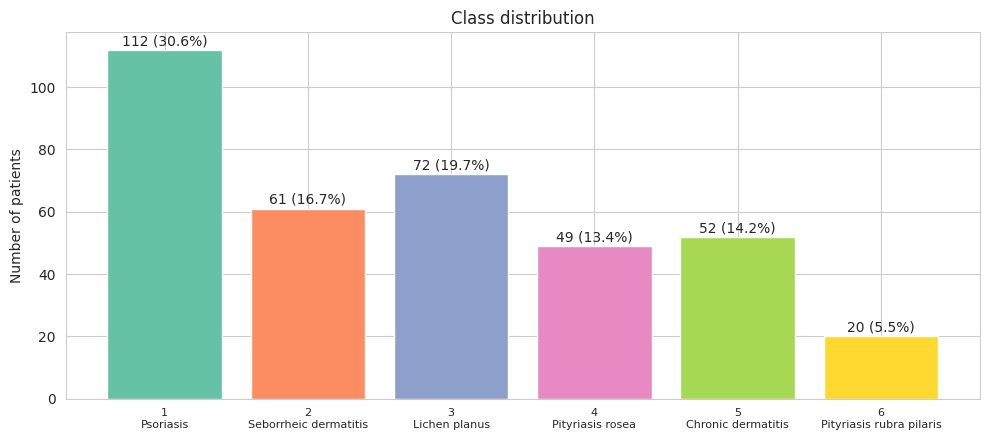

In [ ]:
counts = df["Class"].value_counts().sort_index()
labels = [f"{k}\n{class_names[k]}" for k in counts.index]
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(labels, counts.values, color=sns.color_palette("Set2", 6))
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 1.5, f"{v} ({v/len(df):.1%})", ha="center")
ax.set_ylabel("Number of patients"); ax.set_title("Class distribution")
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()

**Histogram and box plot of Age by disease class**

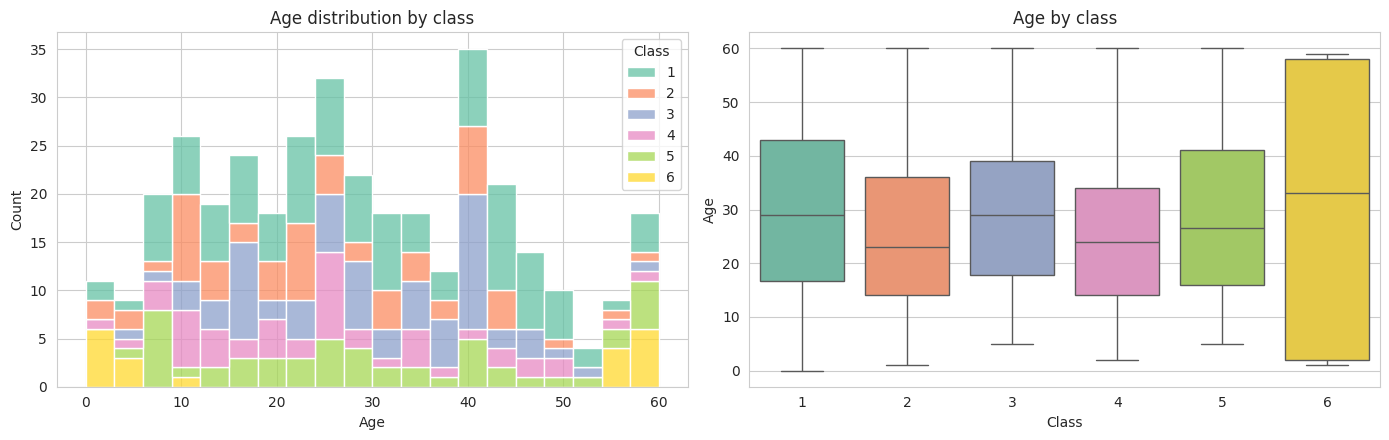

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=df, x="Age", hue="Class", bins=20, palette="Set2", multiple="stack", ax=axes[0])
axes[0].set_title("Age distribution by class")
sns.boxplot(data=df, x="Class", y="Age", palette="Set2", ax=axes[1])
axes[1].set_title("Age by class")
plt.tight_layout(); plt.show()

**Key clinical/histopathological features by class** (mean severity grade per class)

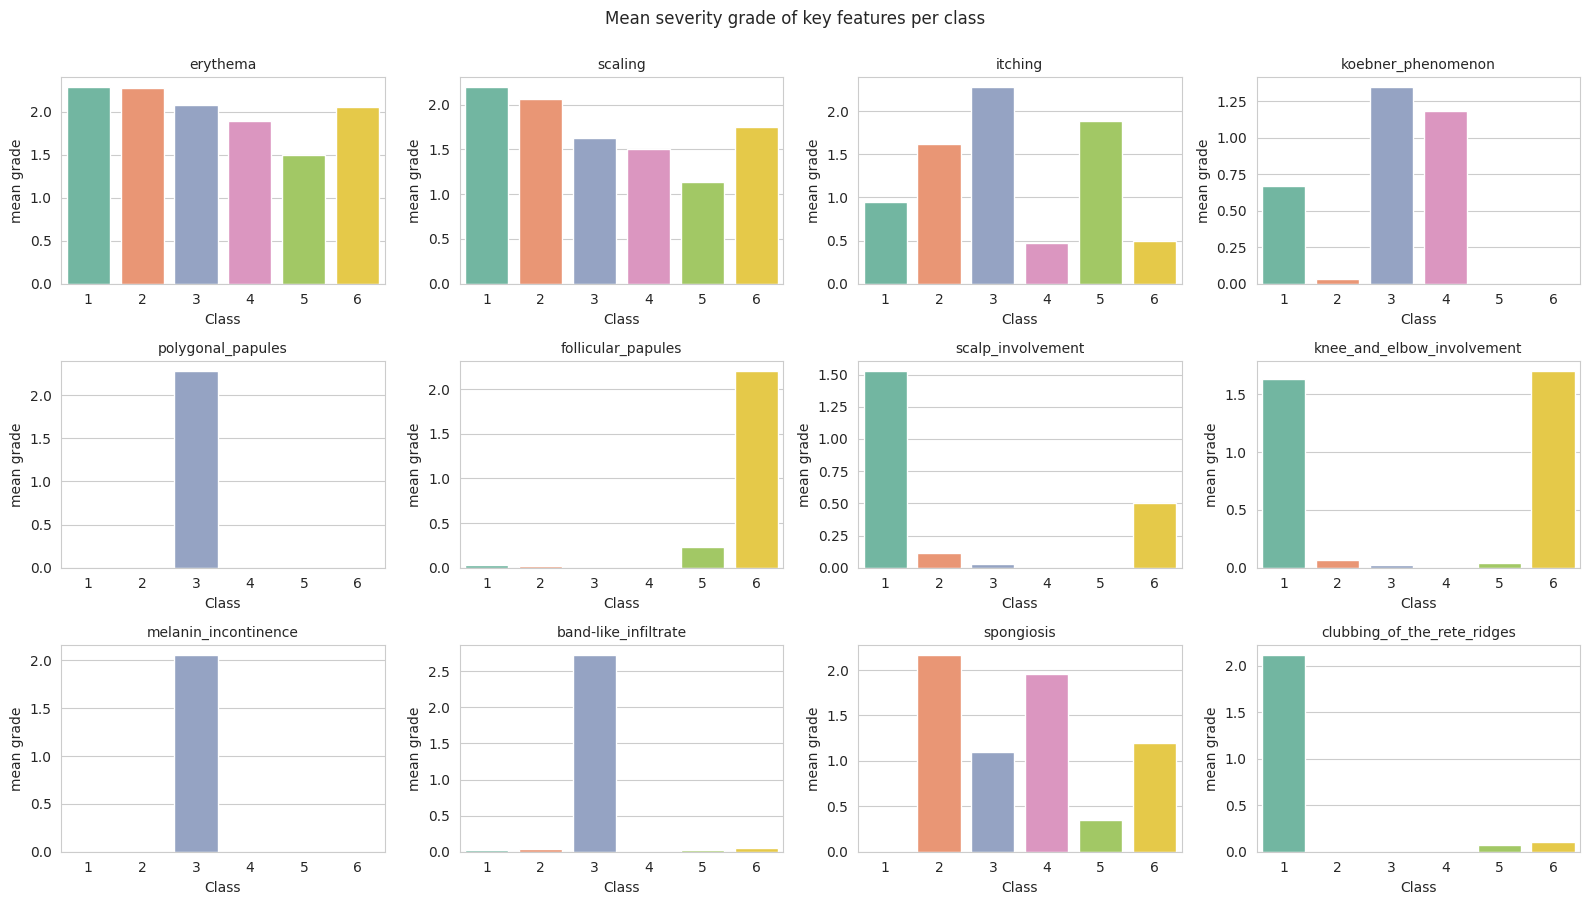

In [ ]:
key = ["erythema", "scaling", "itching", "koebner_phenomenon", "polygonal_papules",
       "follicular_papules", "scalp_involvement", "knee_and_elbow_involvement",
       "melanin_incontinence", "band-like_infiltrate", "spongiosis", "clubbing_of_the_rete_ridges"]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, f in zip(axes.ravel(), key):
    sns.barplot(data=df, x="Class", y=f, palette="Set2", errorbar=None, ax=ax)
    ax.set_title(f, fontsize=10); ax.set_ylabel("mean grade")
plt.suptitle("Mean severity grade of key features per class", y=1.0)
plt.tight_layout(); plt.show()

**Correlation heatmap**

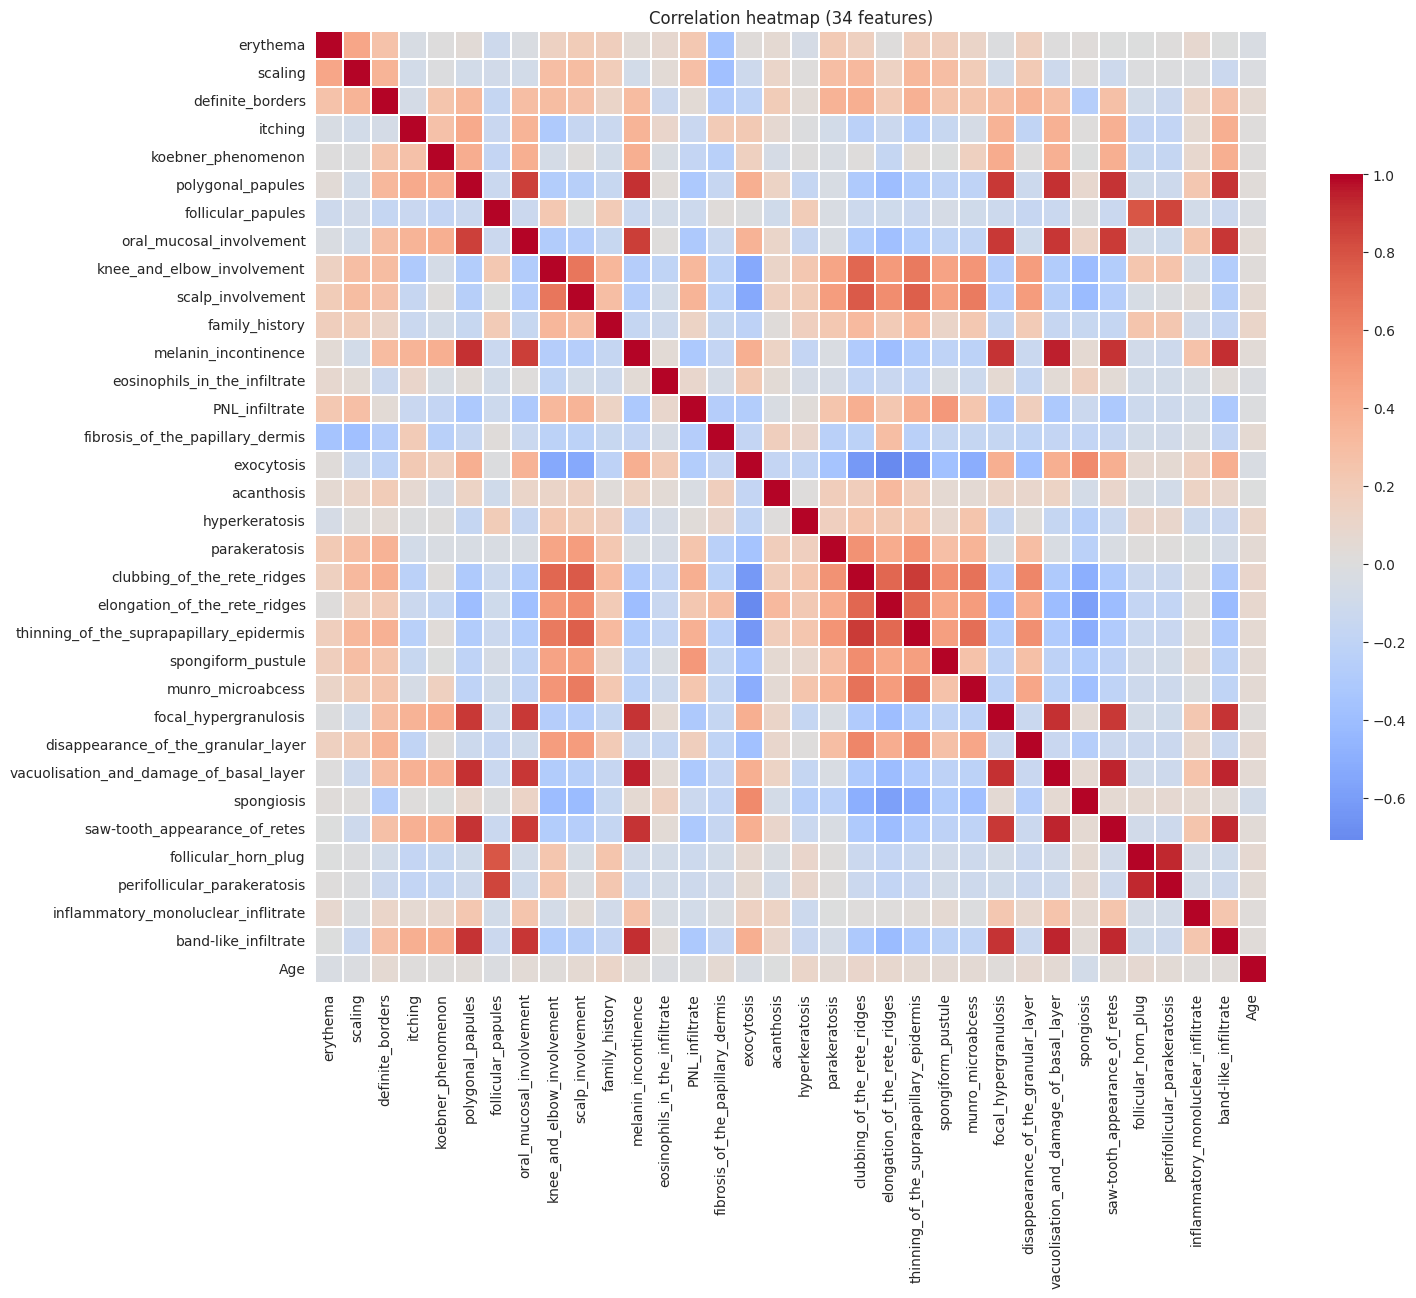

Top 5 positively correlated pairs:
 melanin_incontinence                     vacuolisation_and_damage_of_basal_layer    0.942
vacuolisation_and_damage_of_basal_layer  saw-tooth_appearance_of_retes              0.938
                                         band-like_infiltrate                       0.938
follicular_horn_plug                     perifollicular_parakeratosis               0.929
saw-tooth_appearance_of_retes            band-like_infiltrate                       0.929
dtype: float64

Pairs with |r| > 0.8: 24


In [ ]:
corr = df[features].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7}, linewidths=0.1)
plt.title("Correlation heatmap (34 features)")
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("Top 5 positively correlated pairs:\n", pairs.head(5).round(3))
print("\nPairs with |r| > 0.8:", int((pairs.abs() > 0.8).sum()))

**Observations:** Many histopathological features are strongly correlated with each other (24 pairs have |r| > 0.8; e.g. melanin incontinence, vacuolisation of the basal layer, saw-tooth rete ridges and band-like infiltrate all reach r ≈ 0.93–0.94, because they co-occur in the same disease), so there is redundancy between features. Several features show very different average grades across classes (e.g. polygonal papules and band-like infiltrate for lichen planus, follicular papules for pityriasis rubra pilaris, scalp involvement for seborrheic dermatitis/psoriasis), which suggests the classes are well separable.

## 5. Class imbalance

In [ ]:
ratio = counts.max() / counts.min()
print((counts.rename(index=class_names).to_frame("n").assign(pct=lambda d: (d.n/len(df)*100).round(1))))
print(f"\nLargest/smallest class ratio = {ratio:.1f}:1")

                            n   pct
Class                              
Psoriasis                 112  30.6
Seborrheic dermatitis      61  16.7
Lichen planus              72  19.7
Pityriasis rosea           49  13.4
Chronic dermatitis         52  14.2
Pityriasis rubra pilaris   20   5.5

Largest/smallest class ratio = 5.6:1


**Discussion:** The data are **moderately imbalanced**: psoriasis has 112 patients (30.6%) while pityriasis rubra pilaris has only 20 (5.5%), a ratio of 5.6 to 1. Implications for model training:
- A model can reach decent **accuracy while ignoring the rare class**, so we report per-class precision/recall/F1 and macro-averaged metrics, not accuracy alone.
- The rare class has very few examples (only 4 in a 20% test set), so its metrics are **noisy**: a single mistake changes its recall by 25 points.
- We use a **stratified split** and **stratified cross-validation** so every fold contains all six diseases.
- We use `class_weight="balanced"` where the algorithm supports it (Logistic Regression, SVM, Random Forest) so errors on rare classes are penalised more.

# Task 2: Data Preprocessing

In [ ]:
# Encode the target: classes 1..6 -> 0..5 (scikit-learn expects 0-based class indices)
le = LabelEncoder()
y = le.fit_transform(df["Class"])
X = df[features].values
print("Original labels:", list(le.classes_), "-> encoded:", list(range(len(le.classes_))))

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nClass proportions (train vs test):")
print(pd.DataFrame({"train": np.bincount(y_train)/len(y_train),
                    "test": np.bincount(y_test)/len(y_test)}, index=le.classes_).round(3))

# Standardize (fit on training data only to avoid leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("\nScaled train means (first 3):", X_train_s.mean(axis=0)[:3].round(6),
      "| stds:", X_train_s.std(axis=0)[:3].round(6))

Original labels: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)] -> encoded: [0, 1, 2, 3, 4, 5]
Train: (292, 34) | Test: (74, 34)

Class proportions (train vs test):
   train   test
1  0.305  0.311
2  0.168  0.162
3  0.195  0.203
4  0.134  0.135
5  0.144  0.135
6  0.055  0.054

Scaled train means (first 3): [ 0.  0. -0.] | stds: [1. 1. 1.]


- **Encoding:** `LabelEncoder` maps classes 1–6 to 0–5; we keep the disease names for plots.
- **Stratified 80/20 split** keeps the class proportions the same in train and test.
- **Standardization** (zero mean, unit variance) is essential for distance-based and gradient-based models (KNN, SVM, Logistic Regression) because Age (0–60) would otherwise dominate the 0–3 grade features. Tree-based models do not need it but are given scaled data too for a fair comparison. The scaler is fitted on the training set only.

# Task 3: Model Training and Evaluation
## 1. Train five multiclass models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN (k=5)":           KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)":           SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
}

preds, probas = {}, {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    preds[name] = m.predict(X_test_s)
    probas[name] = m.predict_proba(X_test_s)
    print(f"{name:<22} trained | test accuracy = {accuracy_score(y_test, preds[name]):.4f}")

Logistic Regression    trained | test accuracy = 0.9595
KNN (k=5)              trained | test accuracy = 0.8919
SVM (RBF)              trained | test accuracy = 0.9730
Random Forest          trained | test accuracy = 0.9459
Gradient Boosting      trained | test accuracy = 0.9324


## 2. Overall comparison of the models

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    p, r, f1, _ = precision_recall_fscore_support(y_test, preds[name], average="macro", zero_division=0)
    _, _, wf1, _ = precision_recall_fscore_support(y_test, preds[name], average="weighted", zero_division=0)
    macro_auc = roc_auc_score(y_test, probas[name], multi_class="ovr", average="macro")
    # 5-fold CV on the full data (scaler inside the pipeline -> no leakage)
    cv = cross_val_score(make_pipeline(StandardScaler(), type(m)(**m.get_params())), X, y, cv=skf, scoring="accuracy")
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, preds[name]),
                 "Macro Precision": p, "Macro Recall": r, "Macro F1": f1,
                 "Weighted F1": wf1, "Macro AUC (OvR)": macro_auc,
                 "5-fold CV Acc (mean)": cv.mean(), "CV std": cv.std()})
results = pd.DataFrame(rows).set_index("Model").round(4)
results.sort_values("Macro F1", ascending=False)

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro AUC (OvR),5-fold CV Acc (mean),CV std
Model,,,,,,,,
SVM (RBF),0.9730,0.9722,0.9722,0.9697,0.9730,0.9978,0.9726,0.0174
Logistic Regression,0.9595,0.9615,0.9611,0.9574,0.9606,0.9993,0.9699,0.0202
Random Forest,0.9459,0.9197,0.9417,0.9274,0.9452,0.9984,0.9754,0.0103
Gradient Boosting,0.9324,0.9062,0.9250,0.9125,0.9309,0.9956,0.9699,0.0134
KNN (k=5),0.8919,0.8920,0.8678,0.8717,0.8939,0.9863,0.9562,0.0202


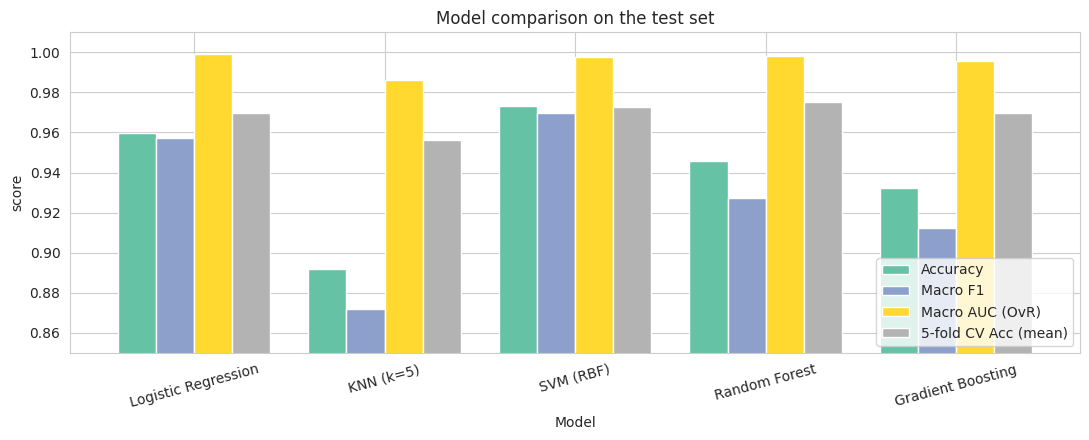

In [ ]:
ax = results[["Accuracy", "Macro F1", "Macro AUC (OvR)", "5-fold CV Acc (mean)"]].plot(
    kind="bar", figsize=(11, 4.5), width=0.8, colormap="Set2")
ax.set_ylim(0.85, 1.01); ax.set_ylabel("score"); ax.set_title("Model comparison on the test set")
plt.xticks(rotation=15); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 3. Precision, Recall and F1-score for every class
(The assignment asks for the per-class report; with six diseases we report all six classes for each model.)

In [ ]:
target_names = [f"{c}-{class_names[c]}" for c in le.classes_]
for name in models:
    print("=" * 78); print(name); print("=" * 78)
    print(classification_report(y_test, preds[name], target_names=target_names, digits=3, zero_division=0))

Logistic Regression
                            precision    recall  f1-score   support

               1-Psoriasis      1.000     1.000     1.000        23
   2-Seborrheic dermatitis      1.000     0.833     0.909        12
           3-Lichen planus      1.000     0.933     0.966        15
        4-Pityriasis rosea      0.769     1.000     0.870        10
      5-Chronic dermatitis      1.000     1.000     1.000        10
6-Pityriasis rubra pilaris      1.000     1.000     1.000         4

                  accuracy                          0.959        74
                 macro avg      0.962     0.961     0.957        74
              weighted avg      0.969     0.959     0.961        74

KNN (k=5)
                            precision    recall  f1-score   support

               1-Psoriasis      1.000     0.957     0.978        23
   2-Seborrheic dermatitis      0.800     0.667     0.727        12
           3-Lichen planus      1.000     0.933     0.966        15
        4-Pity

**Per-class F1 heatmap across models**

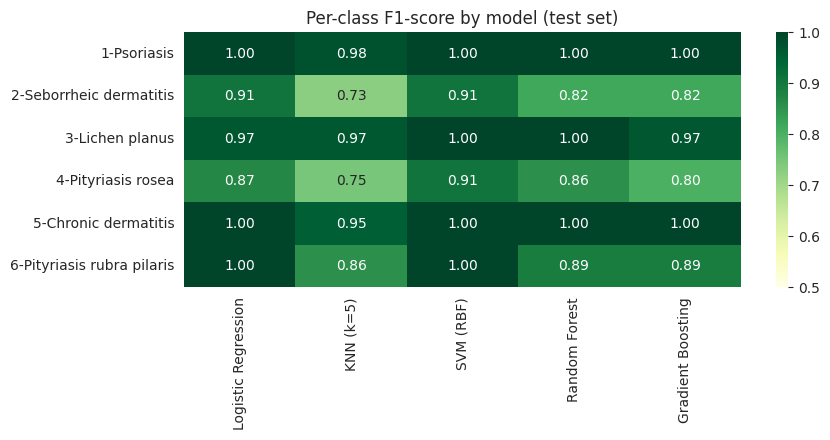

In [ ]:
f1_table = pd.DataFrame({name: precision_recall_fscore_support(y_test, preds[name], zero_division=0)[2]
                         for name in models}, index=[f"{c}-{class_names[c]}" for c in le.classes_])
plt.figure(figsize=(9, 4.5))
sns.heatmap(f1_table, annot=True, fmt=".2f", cmap="YlGn", vmin=0.5, vmax=1.0)
plt.title("Per-class F1-score by model (test set)"); plt.tight_layout(); plt.show()

## 4. Confusion matrices

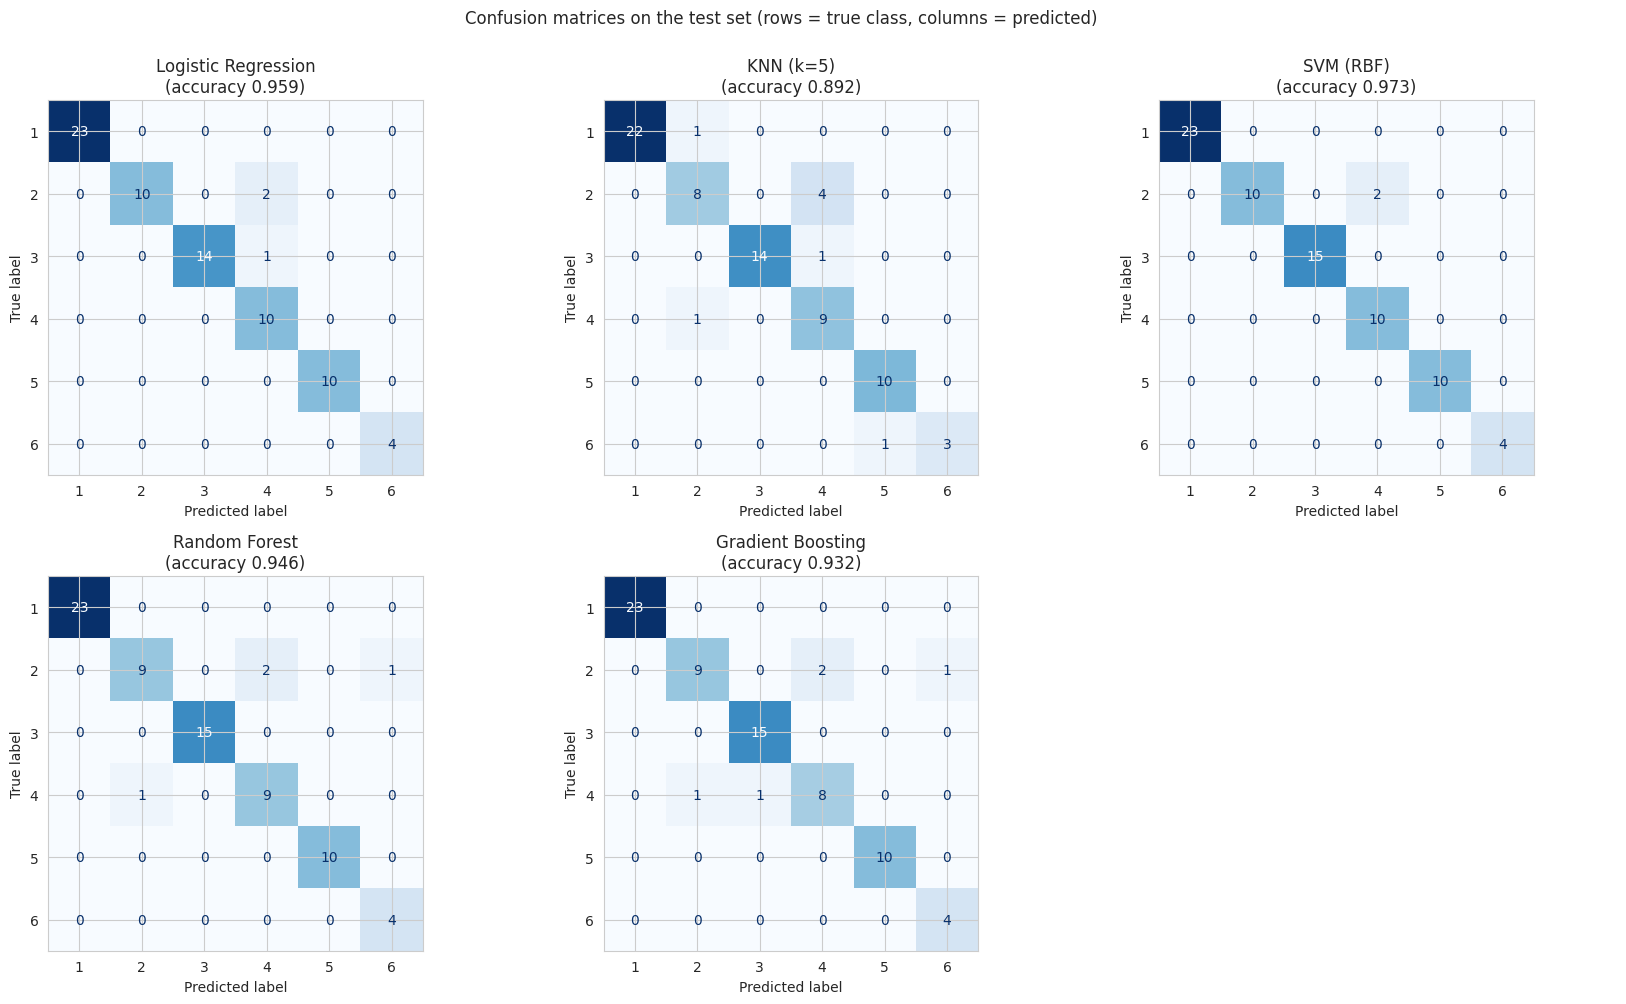

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()
for ax, (name, yp) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, yp)
    ConfusionMatrixDisplay(cm, display_labels=list(le.classes_)).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\n(accuracy {accuracy_score(y_test, yp):.3f})")
axes[-1].axis("off")
plt.suptitle("Confusion matrices on the test set (rows = true class, columns = predicted)", y=1.0)
plt.tight_layout(); plt.show()

## 5. ROC curves and AUC (one-vs-rest)

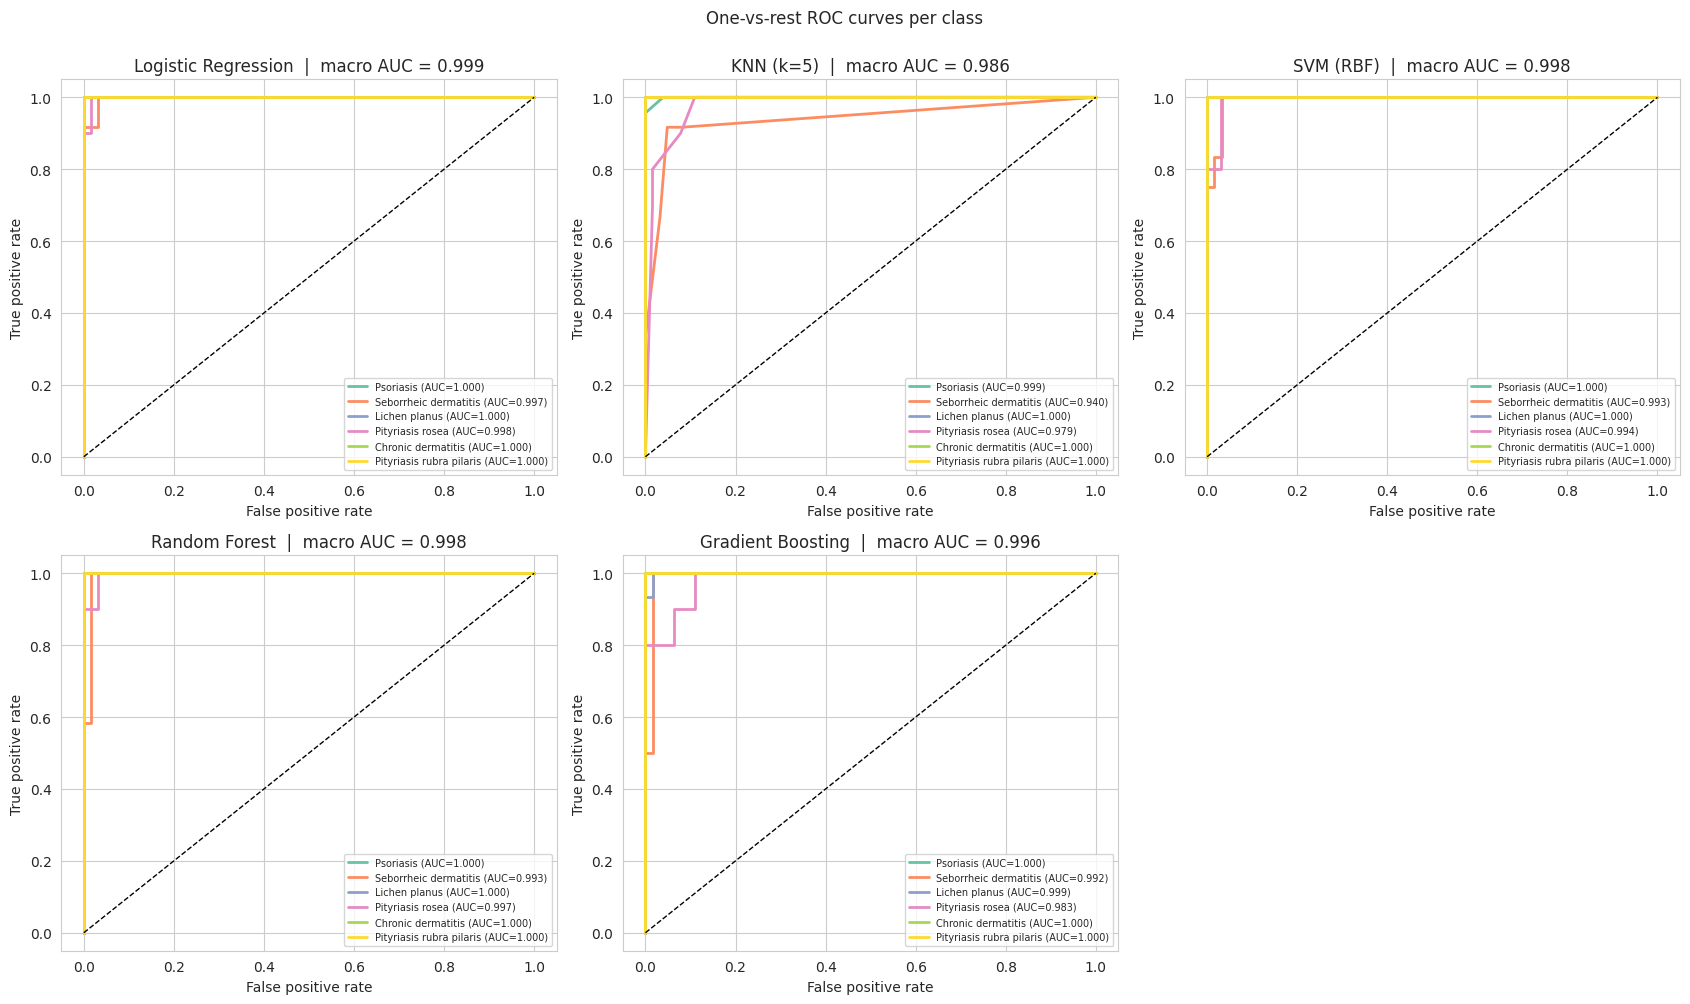

,Logistic Regression,KNN (k=5),SVM (RBF),Random Forest,Gradient Boosting
Psoriasis,1.000000,0.99910,1.00000,1.000000,1.0000
Seborrheic dermatitis,0.997300,0.93950,0.99330,0.993300,0.9919
Lichen planus,1.000000,1.00000,1.00000,1.000000,0.9989
Pityriasis rosea,0.998400,0.97890,0.99380,0.996900,0.9828
Chronic dermatitis,1.000000,1.00000,1.00000,1.000000,1.0000
Pityriasis rubra pilaris,1.000000,1.00000,1.00000,1.000000,1.0000
Macro average,0.999283,0.98625,0.99785,0.998367,0.9956


In [ ]:
y_test_bin = label_binarize(y_test, classes=range(6))
colors = sns.color_palette("Set2", 6)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()
for ax, (name, pr) in zip(axes, probas.items()):
    for i in range(6):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], pr[:, i])
        ax.plot(fpr, tpr, color=colors[i], lw=2,
                label=f"{class_names[i+1]} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{name}  |  macro AUC = {roc_auc_score(y_test, pr, multi_class='ovr'):.3f}")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(fontsize=7, loc="lower right")
axes[-1].axis("off")
plt.suptitle("One-vs-rest ROC curves per class", y=1.0)
plt.tight_layout(); plt.show()

auc_table = pd.DataFrame({name: [roc_auc_score(y_test_bin[:, i], probas[name][:, i]) for i in range(6)]
                          for name in models}, index=[class_names[c] for c in le.classes_]).round(4)
auc_table.loc["Macro average"] = auc_table.mean()
auc_table

## 6. Most important features (Random Forest)

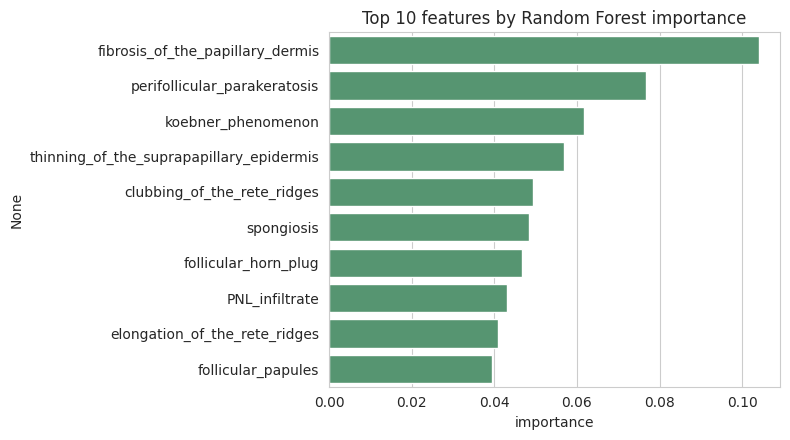

In [ ]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4.5))
sns.barplot(x=imp.values, y=imp.index, color="#4c9f70")
plt.title("Top 10 features by Random Forest importance"); plt.xlabel("importance")
plt.tight_layout(); plt.show()

## Interpretation of results

**Model ranking (test set, 74 patients)**

| Model | Accuracy | Macro F1 | Macro AUC | 5-fold CV accuracy |
|---|---|---|---|---|
| SVM (RBF) | 0.973 | 0.970 | 0.998 | 0.973 ± 0.017 |
| Logistic Regression | 0.959 | 0.957 | 0.999 | 0.970 ± 0.020 |
| Random Forest | 0.946 | 0.927 | 0.998 | 0.984 ± 0.006 |
| Gradient Boosting | 0.932 | 0.913 | 0.996 | 0.970 ± 0.013 |
| KNN (k=5) | 0.892 | 0.872 | 0.986 | 0.956 ± 0.020 |

1. **All five models perform well**, which fits the EDA: the clinical and histopathological grades separate these diseases clearly. The SVM is best on the held-out test set (only 2 of 74 patients wrong), followed by Logistic Regression. KNN is clearly the weakest: it is sensitive to the many redundant, correlated features, which distort distances, and it has no class weighting.
2. **The ranking among the top four is not conclusive.** With 74 test patients, one patient is worth 1.35 accuracy points, and the 5-fold cross-validation (which uses all 366 patients) puts Random Forest first (0.984) with SVM, Logistic Regression and Gradient Boosting within about one standard deviation of each other. The honest conclusion is that SVM, Logistic Regression and Random Forest are all strong choices, and KNN is the one that is reliably worse.
3. **AUC is near 1 for every model and every class** (macro AUC 0.986–0.999), even for models whose accuracy differs by several points. This means the models *rank* patients correctly (the right disease gets the highest probability almost always); the few errors are cases close to a decision boundary between two similar diseases, not a failure to learn the classes. Because accuracy and AUC measure different things, we report both.
4. **Where the errors are:** Psoriasis, lichen planus and chronic dermatitis are classified essentially perfectly by every model except for a few KNN slips. Nearly all remaining errors are **seborrheic dermatitis predicted as pityriasis rosea** (SVM: 2 of 12; KNN: 4 of 12; Random Forest and Gradient Boosting also confuse the two). These two diseases share many clinical and histological features, so this is also the hardest differential diagnosis for dermatologists, which makes the result clinically plausible. Per-class F1 for these two classes is the lowest in every model (0.73–0.91 for seborrheic dermatitis).
5. **Class imbalance:** The rarest class (pityriasis rubra pilaris, 20 patients, 4 in the test set) is classified perfectly by four models. Only KNN, which has no class weighting and relies on 5 neighbours, misses one of its four patients (recall 0.75). The test class is so small that this result is noisy, so it shows that weighting helps rather than proving the rare class is solved.
6. **Medical interpretation:** In this setting the cost of errors differs by disease. Mistaking seborrheic dermatitis for pityriasis rosea (a self-limiting condition) could lead to under-treatment of a chronic condition, so per-class **recall** matters and macro-averaged scores are more meaningful than accuracy. Random Forest importances show that histopathology drives the predictions (fibrosis of the papillary dermis, perifollicular parakeratosis, Koebner phenomenon, thinning of the suprapapillary epidermis, rete-ridge clubbing), which is consistent with dermatological knowledge and supports clinical trust.
7. **Limitations:** Only 366 patients from a single source, a tiny test set, a rare class with 4 test samples, and the histopathological features require a biopsy. Ages that were missing in the original data are already imputed in this copy. The results should be confirmed with external data, and the models should support rather than replace a dermatologist's judgement.
